# Lecture 12, Contaminant transport in a reservoir

> Applying two-dimensional advection&ndash;diffusion (Lecture 11) to a pollutant in a lake

Lecture 10 followed a pollutant down a *river*, where the water moves in one direction and one
coordinate is enough. Lecture 11 then built the two-dimensional advection&ndash;diffusion
equation, its finite-difference kernels, the no-flux ghost cells and the timestepping, and
used them on **ocean heat**. This lecture reuses all of that machinery and asks a hydrological question
instead. A reservoir, a lake, an estuary or a flooded plain is two-dimensional: water spreads sideways as
well as along, and the wind or the inflow stirs it into circulation cells.

- A polluted tributary enters on one side of a reservoir. **Where does the plume go**, and
  does it reach the water-supply intake on the other shore?
- How much of the pollutant is **diluted by dispersion** and how much is **carried by the circulation**?
- How long is the **warning time** at the intake, and how high does the concentration peak?

To keep the two lectures from repeating each other, this one does **not** re-derive the equation or the
discretization. It adds what is specific to surface-water hydrology:

1. what $C$ and $D$ mean for a lake (Section 1),
2. a fast array version of the Lecture 11 solver (Section 2),
3. the shore-respecting circulation of Lecture 11 at reservoir scale, so that **mass is conserved** (Section 3),
4. **stability, conservation and accuracy checks** on the numerical solution (Section 4), and
5. the quantity a water manager actually needs, the **breakthrough curve at an intake** (Section 6).


In [1]:
# Google Colab setup: install the packages this notebook uses.
# Runs only on Colab; skipped in Binder or a local Jupyter install.
import sys
if "google.colab" in sys.modules:
    %pip install -q numpy matplotlib ipywidgets

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from ipywidgets import interact, fixed
import ipywidgets as widgets

# 1) From ocean heat to a dissolved pollutant

Lecture 11 solved

$$\frac{\partial T}{\partial t} = - \vec{u}\cdot\nabla T + \kappa \nabla^{2} T$$

for the temperature $T$ of the ocean. Nothing in this equation says that $T$ is a temperature: it describes any
**passive tracer**, a quantity that is carried by the water without changing the flow. For a dissolved pollutant
the dictionary is

| Lecture 11 (ocean heat) | This lecture (reservoir) |
|:--|:--|
| temperature $T$ | concentration $C$ (for example mg L$^{-1}$) |
| eddy diffusivity $\kappa$ | dispersion coefficient $D$ [m$^2$ s$^{-1}$] |
| ocean gyre | wind-driven circulation cell in the reservoir |
| ocean basin boundaries | shoreline: no water and no pollutant cross it |
| heat content | pollutant mass $M = \iint C\,dx\,dy$ (times depth) |

$$\boxed{\;\frac{\partial C}{\partial t} = - \vec{u}\cdot\nabla C + D \nabla^{2} C\;}$$

Three points are specific to surface-water hydrology:

- **Depth averaging.** $C$ and $\vec{u}$ are averaged over the depth, which is the usual approximation for a
  shallow reservoir whose depth is much smaller than its width.
- **$D$ is dispersion, not molecular diffusion.** Molecular diffusion of a dissolved salt is about $10^{-9}$ m$^2$ s$^{-1}$,
  completely negligible. $D$ lumps together turbulence and the shear of the flow, and for lakes and reservoirs it is
  typically $1$&ndash;$100$ m$^2$ s$^{-1}$, growing with the size of the plume (compare the dispersion coefficient of the river in Lecture 10).
- **Non-divergent flow.** Lecture 11 used $\nabla\cdot\vec{u}=0$ because seawater is incompressible. For a reservoir of uniform depth, with
  small changes in water level neglected (the "rigid lid" approximation), the depth-averaged flow is also non-divergent, so the
  conservation form $-\nabla\cdot(\vec{u}C)$ and the advective form $-\vec{u}\cdot\nabla C$ are equivalent.

As before, $x$ points east and $y$ points north.


# 2) The solver, written for speed

We keep the discretization of Lecture 11 unchanged: centred differences for the first derivatives, the $[1,-2,1]$ kernel for
the second derivatives, ghost cells for the no-flux boundary and forward Euler in time. In Lecture 11 each kernel was slid over the field
with a double Python `for` loop, which is clear but slow. A reservoir run needs hundreds of time steps on a grid of about a thousand cells,
and we want sliders that respond in a second, so here the same differences are written with **array slicing**: `C[1:-1, 2:]` is the field
shifted by one cell to the east, `C[1:-1, :-2]` the field shifted to the west, and so on. The arithmetic is identical.

$$\text{advect}_{j,i} = -\left( u_{j,i}\,\frac{C_{j,i+1}-C_{j,i-1}}{2\Delta x} + v_{j,i}\,\frac{C_{j+1,i}-C_{j-1,i}}{2\Delta y}\right),
\qquad
\text{disperse}_{j,i} = D\left(\frac{C_{j,i+1}-2C_{j,i}+C_{j,i-1}}{\Delta x^{2}} + \frac{C_{j+1,i}-2C_{j,i}+C_{j-1,i}}{\Delta y^{2}}\right)$$


In [3]:
def advect(C, u, v, deltax, deltay):
    """Advective tendency  -(u dC/dx + v dC/dy)  of the interior cells (centred differences)."""
    tendency = np.zeros_like(C)
    dCdx = (C[1:-1, 2:] - C[1:-1, :-2]) / (2 * deltax)
    dCdy = (C[2:, 1:-1] - C[:-2, 1:-1]) / (2 * deltay)
    tendency[1:-1, 1:-1] = -(u[1:-1, 1:-1] * dCdx + v[1:-1, 1:-1] * dCdy)
    return tendency


def disperse(C, D, deltax, deltay):
    """Dispersive tendency  D (d2C/dx2 + d2C/dy2)  of the interior cells."""
    tendency = np.zeros_like(C)
    d2Cdx2 = (C[1:-1, 2:] - 2 * C[1:-1, 1:-1] + C[1:-1, :-2]) / deltax**2
    d2Cdy2 = (C[2:, 1:-1] - 2 * C[1:-1, 1:-1] + C[:-2, 1:-1]) / deltay**2
    tendency[1:-1, 1:-1] = D * (d2Cdx2 + d2Cdy2)
    return tendency


def update_ghostcells(var):
    """No-flux shore: each ghost cell copies its interior neighbour (as in Lecture 11)."""
    var[0, :] = var[1, :]
    var[-1, :] = var[-2, :]
    var[:, 0] = var[:, 1]
    var[:, -1] = var[:, -2]
    return var


class ReservoirModel:
    """Depth-averaged tracer in a closed basin, advected by (u, v) and dispersed by D."""

    def __init__(self, C, deltat, flow, grid, D):
        self.C = [update_ghostcells(C.copy())]
        self.u, self.v = flow.u, flow.v
        self.deltax, self.deltay = grid.deltax, grid.deltay
        self.deltat = deltat
        self.D = D
        self.t = [0.0]

    def timestep(self):
        C = self.C[-1]
        tendency = (advect(C, self.u, self.v, self.deltax, self.deltay)
                    + disperse(C, self.D, self.deltax, self.deltay))
        self.C.append(update_ghostcells(C + self.deltat * tendency))
        self.t.append(self.t[-1] + self.deltat)

    def run(self, steps):
        for _ in range(steps):
            self.timestep()
        return self

A quick check that the sliced version is the formula above: compare one interior cell of a random field with the
explicit five-point expression.

In [4]:
rng = np.random.default_rng(0)
Ctest, utest, vtest = rng.random((8, 9)), rng.random((8, 9)), rng.random((8, 9))
dx_, dy_, D_ = 2.0, 3.0, 0.7
j, i = 4, 5

by_hand = (-(utest[j, i] * (Ctest[j, i+1] - Ctest[j, i-1]) / (2 * dx_)
             + vtest[j, i] * (Ctest[j+1, i] - Ctest[j-1, i]) / (2 * dy_))
           + D_ * ((Ctest[j, i+1] - 2 * Ctest[j, i] + Ctest[j, i-1]) / dx_**2
                   + (Ctest[j+1, i] - 2 * Ctest[j, i] + Ctest[j-1, i]) / dy_**2))
sliced = advect(Ctest, utest, vtest, dx_, dy_)[j, i] + disperse(Ctest, D_, dx_, dy_)[j, i]
print(f"by hand: {by_hand:.12f}   sliced: {sliced:.12f}")

by hand: 0.094779461206   sliced: 0.094779461206


# 3) The reservoir and a circulation that respects the shore

The reservoir is a rectangle $L = 6$ km wide (east&ndash;west) and $2L = 12$ km long (south&ndash;north). As in Lecture 11 the arrays have
one extra ring of ghost cells all round, and the array index $(j, i)$ runs over $(y, x)$.

In [5]:
class grid:
    """Grid of the reservoir: N cells across its width L [m]; the basin is N x 2N cells."""
    def __init__(self, N, L):
        self.N, self.L = N, L
        self.deltax = self.deltay = L / N
        # cell centres, including one ghost cell on every side
        self.xs = (np.arange(N + 2) - 0.5) * self.deltax
        self.ys = (np.arange(2 * N + 2) - 0.5) * self.deltay - L
        self.X, self.Y = np.meshgrid(self.xs, self.ys)
        self.grid = np.zeros(self.X.shape)


my_grid = grid(N=20, L=6e3)             # a 6 km x 12 km reservoir, cells of 300 m
print("array shape (rows y, columns x):", my_grid.grid.shape)

array shape (rows y, columns x): (42, 22)


**Why the circulation must respect the shore.** As in Lecture 11 the velocities come from a streamfunction, $u = \partial\psi/\partial y$ and $v = -\partial\psi/\partial x$,
which is automatically non-divergent, and $\psi$ is chosen to be **zero along all four shores**, so that the shore is a streamline and no water crosses it:

$$\psi(x,y) = -\psi_0 \,\sin\!\left(\frac{\pi x}{L}\right)\sin\!\left(\frac{\pi (y+L)}{2L}\right).$$

This matters more for a pollutant than for a heat budget. If the flow leaked through the shore, **pollutant mass would be created or destroyed at the boundary**: a gyre whose velocities were only zeroed in the
outermost ring of cells made the total mass grow by about a third in 20 days in a test run of this reservoir. The single clockwise cell below has peak speed about $\pi\psi_0/L$, and as before $\psi$ is evaluated at the cell corners so that differencing it gives velocities at the cell centres.

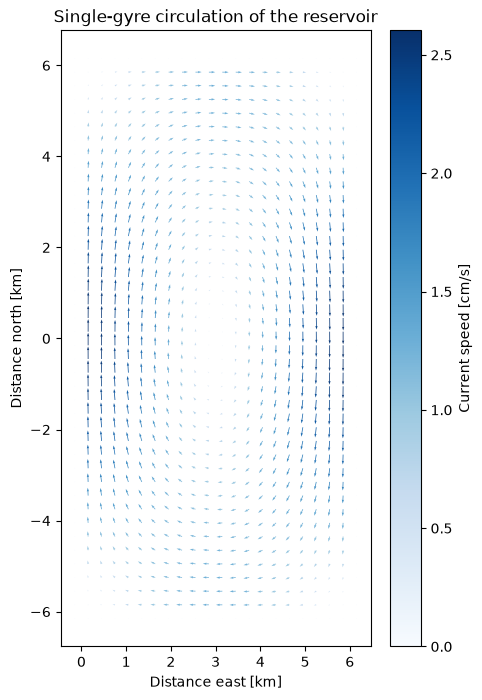

In [6]:
def single_gyre(G, psi0=50.0):
    """Closed-basin circulation cell; psi0 [m2/s] sets its strength."""
    xc = np.append(G.xs - G.deltax / 2, G.xs[-1] + G.deltax / 2).reshape(1, -1)   # cell corners
    yc = np.append(G.ys - G.deltay / 2, G.ys[-1] + G.deltay / 2).reshape(-1, 1)
    stream = -psi0 * np.sin(np.pi * xc / G.L) * np.sin(np.pi * (yc + G.L) / (2 * G.L))

    dpsi_dx = (stream[:, 1:] - stream[:, :-1]) / G.deltax
    dpsi_dy = (stream[1:, :] - stream[:-1, :]) / G.deltay
    u = 0.5 * (dpsi_dy[:, 1:] + dpsi_dy[:, :-1])
    v = -0.5 * (dpsi_dx[1:, :] + dpsi_dx[:-1, :])
    for a in (u, v):                      # no flow in the ghost ring
        a[0, :] = a[-1, :] = a[:, 0] = a[:, -1] = 0
    return u, v


class flowfield:
    """Velocity field of the reservoir. option: "zero" (still water) or "single_gyre"."""
    def __init__(self, G, option="zero"):
        if option == "zero":
            self.u, self.v = np.zeros(G.grid.shape), np.zeros(G.grid.shape)
        elif option == "single_gyre":
            self.u, self.v = single_gyre(G)
        else:
            raise ValueError(option)


still = flowfield(my_grid, "zero")
gyre = flowfield(my_grid, "single_gyre")
speed = np.hypot(gyre.u, gyre.v)

plt.figure(figsize=(5, 8))
plt.quiver(my_grid.X/1e3, my_grid.Y/1e3, gyre.u, gyre.v, speed * 100, cmap="Blues")
plt.colorbar(label="Current speed [cm/s]")
plt.xlabel("Distance east [km]")
plt.ylabel("Distance north [km]")
plt.title("Single-gyre circulation of the reservoir");

# 4) Can we trust the numbers?

Before using the model to answer a water-quality question we check three things.

**Stability.** As in Lecture 11, forward Euler with centred differences needs a **diffusion number** $\mathrm{d} = D\,\Delta t\,(1/\Delta x^{2} + 1/\Delta y^{2}) < 1/2$, and the **grid P&eacute;clet number**
$\mathrm{Pe} = |\vec{u}|\,\Delta x / D$ should be below about $2$ to avoid spurious wiggles (even negative concentrations).

In [7]:
D = 5.0                      # dispersion coefficient [m2/s]
deltat = 60 * 60             # time step: 1 hour [s]

d_number = D * deltat * (1 / my_grid.deltax**2 + 1 / my_grid.deltay**2)
Pe = speed.max() * my_grid.deltax / D
print(f"peak current speed = {speed.max()*100:.1f} cm/s")
print(f"diffusion number d = {d_number:.2f}   (must be < 0.5)")
print(f"grid Peclet number = {Pe:.2f}   (should be < 2)")

peak current speed = 2.6 cm/s
diffusion number d = 0.40   (must be < 0.5)
grid Peclet number = 1.56   (should be < 2)


**Conservation.** With no-flux shores the total pollutant mass $M = \sum C\,\Delta x\,\Delta y$ (over the interior cells, not the ghost cells) must stay constant.
It is the simplest test of a transport model, and it is the one that exposed the flow-field problem above. We will print it in every experiment.

In [8]:
def total_mass(C, G):
    return C[1:-1, 1:-1].sum() * G.deltax * G.deltay      # concentration x area [mg/L x m2]


def plot_field(C, G, flow, title="", vmax=1.0, ax=None, arrows=True):
    ax = ax or plt.gca()
    m = ax.pcolormesh(G.xs/1e3, G.ys/1e3, C, vmin=0, vmax=vmax, cmap="viridis", shading="nearest")
    if arrows and np.any(flow.u):
        ax.quiver(G.X/1e3, G.Y/1e3, flow.u, flow.v, color="white", alpha=0.6)
    ax.set_xlabel("Distance east [km]")
    ax.set_ylabel("Distance north [km]")
    ax.set_title(title)
    return m

# 5) Experiment 1: a spill in still water

First switch the circulation off. A 2 km $\times$ 2 km patch of pollutant ($C = 1$ mg L$^{-1}$) is released at the centre of the reservoir, like a spill from a boat or the outflow of a small drain.
Only dispersion acts, so the patch should spread symmetrically and become more dilute, but not move.

day  0:  peak C = 1.000   mass = 1.0000 x initial
day  2:  peak C = 0.253   mass = 1.0000 x initial
day  8:  peak C = 0.083   mass = 1.0000 x initial
day 20:  peak C = 0.053   mass = 1.0000 x initial


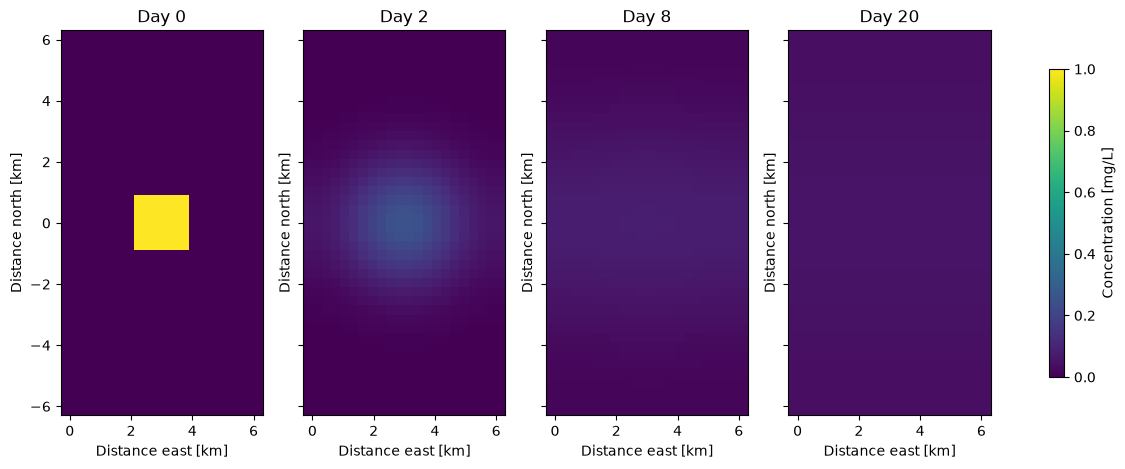

In [9]:
C0 = np.zeros(my_grid.grid.shape)
C0[(abs(my_grid.X - 3e3) < 1e3) & (abs(my_grid.Y - 0.0) < 1e3)] = 1.0

spill = ReservoirModel(C0, deltat, still, my_grid, D).run(24 * 20)       # 20 days

fig, axes = plt.subplots(1, 4, figsize=(15, 5), sharey=True)
for ax, day in zip(axes, [0, 2, 8, 20]):
    m = plot_field(spill.C[day * 24], my_grid, still, title=f"Day {day}", ax=ax)
fig.colorbar(m, ax=axes, label="Concentration [mg/L]", shrink=0.8)

M0 = total_mass(spill.C[0], my_grid)
for day in [0, 2, 8, 20]:
    C = spill.C[day * 24]
    print(f"day {day:2d}:  peak C = {C.max():.3f}   mass = {total_mass(C, my_grid)/M0:.4f} x initial")

**Accuracy check against theory.** For a release in an unbounded domain the plume stays Gaussian and its variance grows linearly,
$\sigma^{2}(t) = \sigma_0^{2} + 2Dt$ in each direction (Fischer et al., 1979). This gives a direct way to measure $D$ from a tracer experiment, and to test the code. We compute the
east&ndash;west variance of the simulated plume and compare it with the theory. (The prediction applies only while the plume is far from the shore; the simulated variance agrees to about 1% over the first day and then falls below the theory
as the plume meets the no-flux boundary.)

In [10]:
def variance_x(C, G):
    w = C[1:-1, 1:-1]
    x = G.X[1:-1, 1:-1]
    xbar = (w * x).sum() / w.sum()
    return (w * (x - xbar) ** 2).sum() / w.sum()

sigma0_sq = variance_x(spill.C[0], my_grid)
for hours in [0, 12, 24, 36, 48]:
    t = hours * 3600.0
    print(f"t = {hours:2d} h:  simulated {variance_x(spill.C[hours], my_grid)/1e6:6.3f} km2"
          f"   theory {(sigma0_sq + 2 * D * t)/1e6:6.3f} km2")

t =  0 h:  simulated  0.263 km2   theory  0.263 km2
t = 12 h:  simulated  0.694 km2   theory  0.695 km2
t = 24 h:  simulated  1.112 km2   theory  1.127 km2
t = 36 h:  simulated  1.482 km2   theory  1.558 km2
t = 48 h:  simulated  1.791 km2   theory  1.990 km2


# 6) Experiment 2: a polluted inflow stirred by the circulation

Now the gyre is switched on. A polluted tributary discharges along the northern part of the reservoir: we start with a band of polluted water ($C=1$)
between $y = +1$ km and $y = +3$ km spanning the whole width, with clean water elsewhere. We run the same band with and without the circulation.

day  0:  mass = 1.0000 x initial
day  3:  mass = 0.9989 x initial
day  8:  mass = 0.9983 x initial
day 20:  mass = 0.9984 x initial


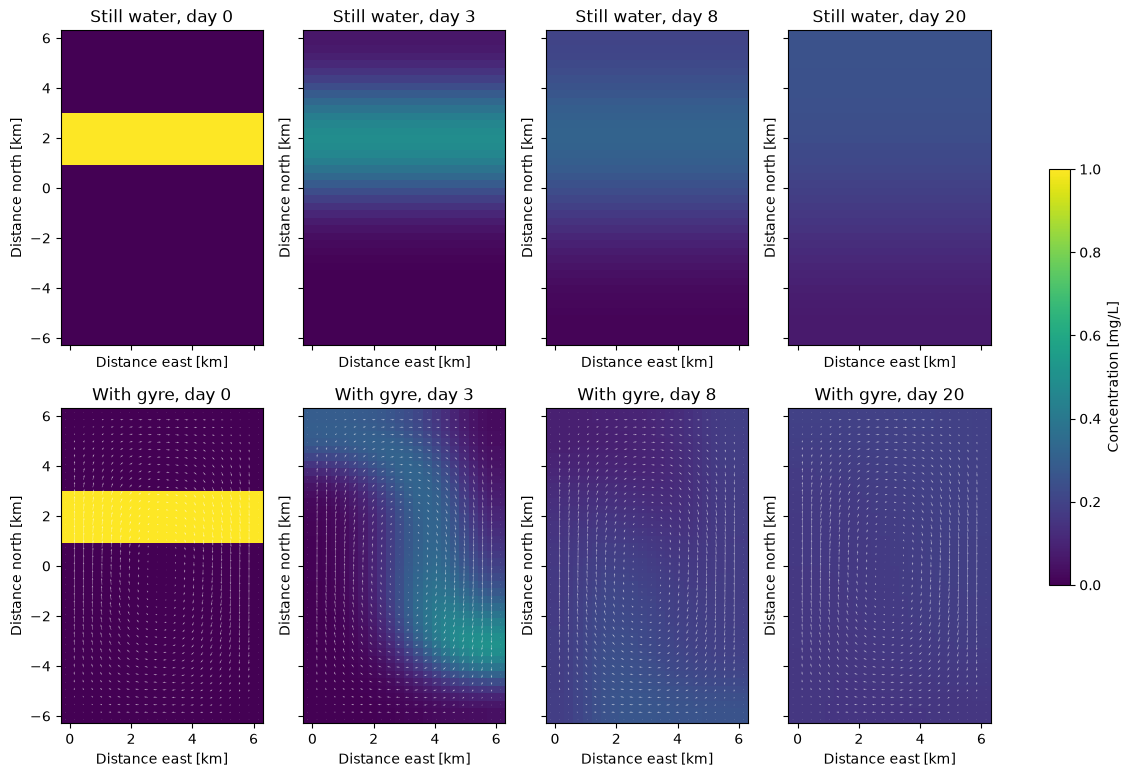

In [11]:
C0_band = np.zeros(my_grid.grid.shape)
C0_band[(my_grid.Y > 1e3) & (my_grid.Y < 3e3)] = 1.0

with_gyre = ReservoirModel(C0_band, deltat, gyre, my_grid, D).run(24 * 20)     # 20 days
no_gyre = ReservoirModel(C0_band, deltat, still, my_grid, D).run(24 * 20)      # same band, still water

fig, axes = plt.subplots(2, 4, figsize=(15, 9), sharex=True, sharey=True)
for col, day in enumerate([0, 3, 8, 20]):
    plot_field(no_gyre.C[day * 24], my_grid, still, title=f"Still water, day {day}", ax=axes[0, col])
    m = plot_field(with_gyre.C[day * 24], my_grid, gyre, title=f"With gyre, day {day}", ax=axes[1, col])
fig.colorbar(m, ax=axes, label="Concentration [mg/L]", shrink=0.6)

M0 = total_mass(with_gyre.C[0], my_grid)
for day in [0, 3, 8, 20]:
    print(f"day {day:2d}:  mass = {total_mass(with_gyre.C[day * 24], my_grid)/M0:.4f} x initial")

In still water the band simply thickens and fades from both edges (the one-dimensional problem of Lecture 9, in $y$). With the gyre the pollutant is
**advected**: the circulation carries the band clockwise, down the eastern side of the reservoir and into its south-east part within about three days, and stretches it as it goes. Dispersion
then smooths the plume. Advection moves and stretches the pollutant, dispersion mixes it, and together they spread a plume much faster than dispersion alone.
By day 20 both runs are roughly uniform, at about one sixth of the initial concentration, because the 2 km band covers one sixth of the basin's area.

The mass stays constant to within a fraction of a percent. The small drift comes from writing advection in the $-\vec{u}\cdot\nabla C$ form rather than in exact flux form; a finite-volume scheme would remove it.

### A water-supply intake

Now the question a water manager asks: *if the intake is at the south-east corner of the reservoir ($x = 5.5$ km, $y = -5.0$ km), what concentration does it see, and when?*
We read the concentration of the nearest grid cell out of the stored model fields to obtain a **breakthrough curve**, the reservoir counterpart of the concentration-versus-time curve at a downstream gauge in Lecture 10.

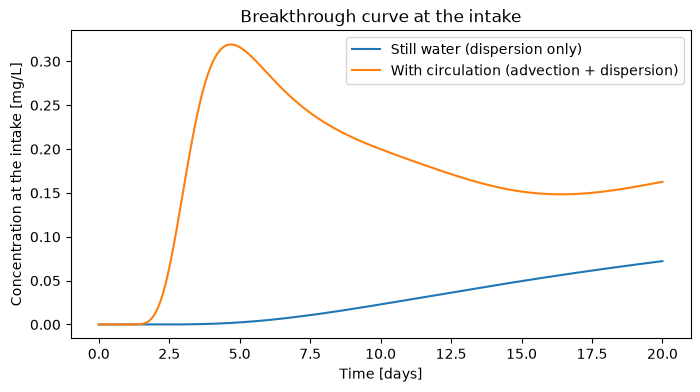

In [12]:
def nearest_cell(G, x, y):
    return np.argmin(abs(G.ys - y)), np.argmin(abs(G.xs - x))

jj, ii = nearest_cell(my_grid, 5.5e3, -5.0e3)
time_days = np.array(with_gyre.t) / 86400

plt.figure(figsize=(8, 4))
plt.plot(time_days, [C[jj, ii] for C in no_gyre.C], label="Still water (dispersion only)")
plt.plot(time_days, [C[jj, ii] for C in with_gyre.C], label="With circulation (advection + dispersion)")
plt.xlabel("Time [days]")
plt.ylabel("Concentration at the intake [mg/L]")
plt.title("Breakthrough curve at the intake")
plt.legend();

In still water the intake sees almost nothing for the first week and only a slow rise afterwards. With the circulation, a pulse
of polluted water reaches the intake after about two days and peaks at roughly 0.3 mg/L after about five days: several times higher
than the still-water value at day 20, and much earlier. The pulse then declines as the plume is stirred through the rest of the
basin and diluted. For a water-supply operator the circulation, not dispersion, sets the warning time and the peak concentration,
which is why a two-dimensional model is needed here and a one-dimensional river model is not enough.

### Interactive version

Choose the circulation and the dispersion coefficient, and move the time slider. (Keep $D \le 6$ m$^2$ s$^{-1}$ so that the explicit scheme stays stable with the one-hour time step.)

In [13]:
flows = {"still water": still, "gyre": gyre}


def explore(days, flow, D):
    model = ReservoirModel(C0_band, deltat, flows[flow], my_grid, D).run(int(days * 86400 / deltat))
    plt.figure(figsize=(6, 8))
    m = plot_field(model.C[-1], my_grid, flows[flow], vmax=1.0)
    plt.colorbar(m, label="Concentration [mg/L]")
    plt.title(f"{flow}, D = {D} m2/s, day {days}")
    plt.show()


interact(explore,
         days=widgets.IntSlider(description="Days", value=3, min=0, max=20, step=1),
         flow=widgets.Dropdown(description="Flow", options=list(flows), value="gyre"),
         D=widgets.FloatSlider(description="D [m2/s]", value=5, min=1, max=6, step=1));

interactive(children=(IntSlider(value=3, description='Days', max=20), Dropdown(description='Flow', index=1, op…

# 7) Try it yourself

- Move the polluted band to the south of the reservoir, or release a single patch at the intake and see how long it takes
  to leave. Does the answer change if the gyre turns the other way (change the sign of `psi0`)?
- Increase the strength of the circulation (`psi0`) and use the stability check of Section 4 to see when you must shorten the time step.
- Add a second intake and compare the breakthrough curves. Which location is safer?
- Use the variance test of Section 5 on a run with a different $D$, and recover $D$ from the slope of $\sigma^{2}(t)$.
- *Optional:* build a **two-gyre** flow field by replacing $\sin(\pi(y+L)/2L)$ in the streamfunction with $\sin(\pi(y+L)/L)$, which gives
  two counter-rotating cells, and check that nothing crosses the shores.
- *Optional:* add a first-order decay term $-kC$ to the right-hand side (for a non-conservative pollutant such as bacteria),
  and check how the total mass now changes with time.


```{note} Sources
The numerical method (centred finite differences, no-flux ghost cells, forward Euler timestepping, streamfunction-based flow) is the one of Lecture 11, which is adapted
from the 2-D advection&ndash;diffusion / ocean-heat-transport lecture in the MIT course
[*Introduction to Computational Thinking*](https://computationalthinking.mit.edu)
(Edelman, Sanders & van der Plas; climate lectures by Henri Drake &mdash; original
code, in Julia:
[simplEarth](https://github.com/hdrake/simplEarth/blob/master/4_ocean_heat_transport.jl)),
by way of the
[*Climate of the Ocean*](https://github.com/florianboergel/climateoftheocean) course.
The hydrological framing (a pollutant in a reservoir, the dispersion coefficient, the closed-basin circulation, the stability, conservation and variance checks,
the intake breakthrough curve) and the text were written for **CE524 Applied Hydroclimatology**; the reservoir geometry and the parameter values are illustrative.

**Theory.**
Fischer, H. B., List, E. J., Koh, R. C. Y., Imberger, J., & Brooks, N. H. (1979).
*Mixing in Inland and Coastal Waters*.
Chapra, S. C. (1997). *Surface Water-Quality Modeling*. McGraw-Hill.

Text under CC BY-SA 4.0, code additionally under the MIT License; full attribution and per-lecture provenance in
[CREDITS.md](https://github.com/drvivekhydro/hydroclimatology/blob/main/CREDITS.md).
```